# Experiment 6: Implementation of A* Search Algorithm

**Department of Computer Science and Engineering (Data Science)**  
**Subject**: Artificial Intelligence (DJ19DSC502)  
**Topic**: A* Pathfinding on Indian City Road Network with Geographical Heuristics  

---

## 1. Aim
To implement and analyze the **A* Search Algorithm** to find the optimal path between Indian cities using real geographical coordinates from `city_latitude_longitude.xlsx`. The implementation incorporates:
1. **India Map Visualization**: Full geographical boundary outline of India for realistic spatial context and visibility.
2. **Heuristic 1**: Great-Circle / Haversine Spherical Distance
3. **Heuristic 2**: Equirectangular Projected Euclidean Distance
4. **Interactive User Interface**: Dynamic selection of start and destination cities with fuzzy matching
5. **Step-by-Step Visualization**: Dynamic Matplotlib animation tracking every node expansion, active path, frontier state, and optimal route.
6. **Comparative Analysis**: Quantitative evaluation of both heuristics regarding admissibility, search efficiency, and nodes expanded.

---

## 2. Theoretical Foundations

### 2.1 The A* Search Evaluation Function
A* is an informed search algorithm combining the advantages of Uniform Cost Search (Dijkstra's) and Greedy Best-First Search. At any node $n$, its total priority score $f(n)$ is:

$$f(n) = g(n) + h(n)$$

Where:
- **$g(n)$**: Exact accumulated path cost from the start node $s$ to node $n$.
- **$h(n)$**: Estimated cost of the cheapest path from node $n$ to the goal node.
- **$f(n)$**: Estimated total cost of the lowest-cost solution passing through $n$.

### 2.2 Mathematical Formulations of the Heuristics

#### Heuristic 1: Great-Circle / Haversine Distance ($h_1$)
Computes the spherical geodesic distance across the Earth's curved surface ($R = 6371.0\text{ km}$):

$$\Delta \phi = \text{rad}(\text{lat}_2 - \text{lat}_1), \quad \Delta \lambda = \text{rad}(\text{lon}_2 - \text{lon}_1)$$
$$a = \sin^2\left(\frac{\Delta \phi}{2}\right) + \cos(\text{rad}(\text{lat}_1)) \cos(\text{rad}(\text{lat}_2)) \sin^2\left(\frac{\Delta \lambda}{2}\right)$$
$$c = 2 \cdot \text{arctan2}(\sqrt{a}, \sqrt{1 - a})$$
$$h_1 = R \cdot c$$

**Admissibility & Consistency Proof**:
- *Admissibility*: The geodesic line on a sphere represents the absolute minimum distance between two surface points. Because physical road distance $c^*(n) \ge h_1(n)$, $h_1$ never overestimates the true remaining cost ($0 \le h_1(n) \le c^*(n)$).
- *Consistency*: The spherical metric adheres to the triangle inequality $h_1(u) \le c(u, v) + h_1(v)$ for any step $u \to v$.

#### Heuristic 2: Equirectangular Projected Euclidean Distance ($h_2$)
Projects spherical coordinates onto a locally flat Cartesian plane with mid-latitude scaling:

$$\phi_m = \text{rad}\left(\frac{\text{lat}_1 + \text{lat}_2}{2}\right)$$
$$x = \Delta \lambda \cdot \cos(\phi_m) \cdot R, \quad y = \Delta \phi \cdot R$$
$$h_2 = \sqrt{x^2 + y^2}$$

**Admissibility**: Within the geographic latitudes of India ($8^\circ\text{N} - 36^\circ\text{N}$), this flat-Earth approximation closely approximates geodesic distance without exceeding physical road lengths, offering a computationally efficient, admissible alternative.

---

In [13]:
# =====================================================================
# CELL 1: Environment Setup, Dataset Loading & Geographical Map Data
# =====================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display
import heapq
import math
import difflib
import time
import json
import os

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

# 1. Load City Coordinates
EXCEL_FILE = 'city_latitude_longitude.xlsx'
df_cities = pd.read_excel(EXCEL_FILE)

city_coords = {}
for _, row in df_cities.iterrows():
    city_coords[str(row['city']).strip()] = (float(row['latitude']), float(row['longitude']))

print(f" Loaded {len(city_coords)} Indian cities from {EXCEL_FILE}.")
print("Sample cities:")
for c in list(city_coords.keys())[:6]:
    lat, lon = city_coords[c]
    print(f"  • {c:15s}: ({lat:.2f}° N, {lon:.2f}° E)")

# 2. Load India Boundary GeoJSON for geographical basemap outline
BOUNDARY_FILE = 'india_boundary.json'
india_polygons = []
try:
    if os.path.exists(BOUNDARY_FILE):
        with open(BOUNDARY_FILE, 'r', encoding='utf-8') as f:
            geo_data = json.load(f)
    else:
        import urllib.request
        url = 'https://raw.githubusercontent.com/HindustanTimesLabs/shapefiles/master/india/country/india.json'
        with urllib.request.urlopen(url, timeout=5) as resp:
            geo_data = json.loads(resp.read().decode())
    geom = geo_data['features'][0]['geometry']
    india_polygons = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
    print(f" Loaded India map boundary ({len(india_polygons)} polygon rings) for basemap rendering.")
except Exception as e:
    print(f" Note: Could not load India boundary ({e}). Continuing with coordinate grid.")


 Loaded 46 Indian cities from city_latitude_longitude.xlsx.
Sample cities:
  • Mumbai         : (19.07° N, 72.88° E)
  • Pune           : (18.52° N, 73.86° E)
  • Nashik         : (20.00° N, 73.79° E)
  • Panaji (Goa)   : (15.49° N, 73.83° E)
  • Virar          : (19.46° N, 72.81° E)
  • Palghar        : (19.69° N, 72.77° E)
 Loaded India map boundary (28 polygon rings) for basemap rendering.


In [14]:
# =====================================================================
# CELL 2: Pure-Python Graph Construction (Road Network)
# =====================================================================

def haversine_km(lat1, lon1, lat2, lon2):
    """Calculate geodesic spherical distance in kilometers."""
    R = 6371.0
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    
    a = math.sin(dphi / 2.0)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2.0)**2
    c = 2.0 * math.atan2(math.sqrt(a), math.sqrt(1.0 - a))
    return R * c

# Build an authentic, connected Indian road network:
# 1. Connect each city to its k=4 nearest neighbors
# 2. Add vital national highway corridors (e.g. connecting eastern & northern hubs)
road_graph = {c: {} for c in city_coords}

# Step 1: k=4 nearest geographic neighbors
for c1, (lat1, lon1) in city_coords.items():
    distances = []
    for c2, (lat2, lon2) in city_coords.items():
        if c1 != c2:
            d = haversine_km(lat1, lon1, lat2, lon2)
            distances.append((d, c2))
    distances.sort()
    for d, c2 in distances[:4]:
        # Edge cost is realistic road distance (~1.15x haversine straight-line distance)
        road_dist = round(d * 1.15, 1)
        road_graph[c1][c2] = road_dist
        road_graph[c2][c1] = road_dist

# Step 2: Add essential National Highway arterial corridors
highway_links = [
    ("Kolkata", "Dibrugarh"),      # Eastern Assam / Northeast Highway link
    ("Patna", "Dibrugarh"),        # NH 27 East-West corridor to Northeast
    ("Pune", "Solapur"),           # NH 65 Pune - Hyderabad corridor
    ("Solapur", "Hyderabad"),      # NH 65 continuation
    ("Hyderabad", "Visakhapatnam"),# NH 16 East Coast link
    ("Mumbai", "Surat"),           # Western corridor
    ("Delhi", "Agra") if "Delhi" in city_coords else ("New Delhi", "Agra"), # Yamuna Expressway
    ("Agra", "Jhansi"),            # NH 44 North-South corridor
    ("Jhansi", "Nagpur"),          # NH 44 continuation
    ("Nagpur", "Hyderabad"),       # NH 44 continuation to South
    ("Bangalore", "Chennai"),      # South arterial
    ("Bangalore", "Mysore")        # Bangalore-Mysore Expressway
]

for u, v in highway_links:
    if u in city_coords and v in city_coords:
        lat1, lon1 = city_coords[u]
        lat2, lon2 = city_coords[v]
        d = round(haversine_km(lat1, lon1, lat2, lon2) * 1.15, 1)
        road_graph[u][v] = d
        road_graph[v][u] = d

# Step 3: Verify single connected component via BFS
def verify_connectivity(graph, start_node):
    visited = set([start_node])
    queue = [start_node]
    while queue:
        curr = queue.pop(0)
        for nbr in graph[curr]:
            if nbr not in visited:
                visited.add(nbr)
                queue.append(nbr)
    return visited

sample_start = list(city_coords.keys())[0]
reachable_cities = verify_connectivity(road_graph, sample_start)
total_edges = sum(len(neighbors) for neighbors in road_graph.values()) // 2

print(f" Road network successfully constructed:")
print(f"  • Total Cities (Vertices |V|): {len(city_coords)}")
print(f"  • Total Road Links (Edges |E|): {total_edges}")
print(f"  • Fully Connected: {len(reachable_cities) == len(city_coords)} ({len(reachable_cities)}/{len(city_coords)} cities reachable)")


 Road network successfully constructed:
  • Total Cities (Vertices |V|): 46
  • Total Road Links (Edges |E|): 130
  • Fully Connected: True (46/46 cities reachable)


In [15]:
# =====================================================================
# CELL 3: Heuristic Functions (H1: Haversine, H2: Euclidean)
# =====================================================================

def heuristic_1(city_a, city_b, coords):
    """
    Heuristic 1: Great-Circle / Haversine Spherical Distance (km).
    Guaranteed to be admissible and consistent on Earth's surface.
    """
    if city_a == city_b:
        return 0.0
    lat1, lon1 = coords[city_a]
    lat2, lon2 = coords[city_b]
    return haversine_km(lat1, lon1, lat2, lon2)

def heuristic_2(city_a, city_b, coords):
    """
    Heuristic 2: Equirectangular Projected Euclidean Distance (km).
    Projects coordinates onto a local 2D plane with mid-latitude correction.
    """
    if city_a == city_b:
        return 0.0
    lat1, lon1 = coords[city_a]
    lat2, lon2 = coords[city_b]
    R = 6371.0
    
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    lambda1, lambda2 = math.radians(lon1), math.radians(lon2)
    phi_m = (phi1 + phi2) / 2.0
    
    x = (lambda2 - lambda1) * math.cos(phi_m) * R
    y = (phi2 - phi1) * R
    return math.sqrt(x**2 + y**2)

# Verification test on sample city pair
c1, c2 = "Mumbai", "New Delhi"
h1_val = heuristic_1(c1, c2, city_coords)
h2_val = heuristic_2(c1, c2, city_coords)
print(f"Heuristic Verification ({c1} -> {c2}):")
print(f"  • H1 (Haversine Distance): {h1_val:.2f} km")
print(f"  • H2 (Euclidean Distance): {h2_val:.2f} km")
print(f"  • Absolute Difference:     {abs(h1_val - h2_val):.2f} km")
print(f"  • H(Goal, Goal) = {heuristic_1(c1, c1, city_coords):.1f} km (Strictly Admissible)")


Heuristic Verification (Mumbai -> New Delhi):
  • H1 (Haversine Distance): 1148.27 km
  • H2 (Euclidean Distance): 1148.58 km
  • Absolute Difference:     0.32 km
  • H(Goal, Goal) = 0.0 km (Strictly Admissible)


In [16]:
# =====================================================================
# CELL 4: A* Search Algorithm with Full Path and Node Expansion Tracking
# =====================================================================

def astar_search(start_city, goal_city, graph, coords, heuristic_fn, heuristic_name="H"):
    """
    A* Search Algorithm with step-by-step state capture for complete visualization.
    
    Parameters:
        start_city: Starting city name
        goal_city: Target destination city name
        graph: Adjacency list with edge weights (distances)
        coords: Dictionary of city coordinates (lat, lon)
        heuristic_fn: Function (city_a, city_b, coords) -> estimated distance
        heuristic_name: Label for display
        
    Returns:
        optimal_path: List of cities in the optimal route
        total_cost: Total path distance in km
        history: List of detailed step snapshots for visualization & auditing
        closed_set: Set of all expanded nodes
        run_time: Execution duration in milliseconds
    """
    start_time = time.perf_counter()
    
    # Priority Queue elements: (f_score, counter, current_node, path, g_score)
    # The counter ensures reliable tie-breaking without comparing city names or paths
    counter = 0
    start_h = heuristic_fn(start_city, goal_city, coords)
    start_f = 0.0 + start_h
    
    # pq holds: (f, counter, city, path_so_far, g)
    open_queue = [(start_f, counter, start_city, [start_city], 0.0)]
    
    # Track lowest g_score known for each node
    best_g = {start_city: 0.0}
    
    # Closed list (nodes whose optimal path is finalized)
    closed_set = set()
    
    # History log to record each expansion step
    history = []
    
    optimal_path = None
    total_cost = float('inf')
    
    while open_queue:
        current_f, _, current_node, current_path, current_g = heapq.heappop(open_queue)
        
        # If node already finalized with a better g, bypass stale entry
        if current_node in closed_set:
            continue
            
        # Finalize current node
        closed_set.add(current_node)
        current_h = heuristic_fn(current_node, goal_city, coords)
        
        # Snapshot current frontier (unique open cities)
        frontier_snapshot = list(set([item[2] for item in open_queue if item[2] not in closed_set]))
        
        # Goal Test: Strictly evaluated upon POP to guarantee optimality
        if current_node == goal_city:
            optimal_path = current_path
            total_cost = current_g
            history.append({
                'step': len(history) + 1,
                'current_node': current_node,
                'g': current_g,
                'h': current_h,
                'f': current_f,
                'path': current_path,
                'frontier': frontier_snapshot,
                'closed': list(closed_set),
                'children_evaluated': [],
                'is_goal': True
            })
            break
            
        # MoveGen: Expand neighbors
        children_evaluated = []
        for neighbor, edge_weight in graph[current_node].items():
            if neighbor in closed_set:
                continue
                
            new_g = current_g + edge_weight
            
            # If discovered shorter path to neighbor, update best_g and enqueue
            if neighbor not in best_g or new_g < best_g[neighbor]:
                best_g[neighbor] = new_g
                counter += 1
                neighbor_h = heuristic_fn(neighbor, goal_city, coords)
                neighbor_f = new_g + neighbor_h
                new_path = current_path + [neighbor]
                
                heapq.heappush(open_queue, (neighbor_f, counter, neighbor, new_path, new_g))
                children_evaluated.append({
                    'city': neighbor,
                    'edge_weight': edge_weight,
                    'new_g': new_g,
                    'h': neighbor_h,
                    'f': neighbor_f
                })
        
        # Record step in history
        history.append({
            'step': len(history) + 1,
            'current_node': current_node,
            'g': current_g,
            'h': current_h,
            'f': current_f,
            'path': current_path,
            'frontier': frontier_snapshot,
            'closed': list(closed_set),
            'children_evaluated': children_evaluated,
            'is_goal': False
        })
    
    elapsed_ms = (time.perf_counter() - start_time) * 1000.0
    return optimal_path, total_cost, history, closed_set, elapsed_ms

print(" A* Search Engine with detailed step history logging loaded.")


 A* Search Engine with detailed step history logging loaded.


In [17]:
# =====================================================================
# CELL 5: Step-by-Step Visualization Engine (Option A: Interactive Animation with India Map)
# =====================================================================

def render_astar_animation(coords, graph, history, optimal_path, start_city, goal_city, heuristic_name, india_polygons=None):
    """
    Builds an interactive Matplotlib animation tracking every node expansion and active path
    overlaid on the geographical map of India.
    Returns an interactive HTML5/JS player with Play, Pause, Step, and Slider controls.
    """
    fig, ax = plt.subplots(figsize=(12, 11), dpi=100)
    fig.patch.set_facecolor('#090d16') # Deep navy ocean background
    ax.set_facecolor('#090d16')
    
    # 0. Draw India Geographical Landmass Boundary
    if india_polygons:
        for poly in india_polygons:
            ring = poly[0]
            r_lons = [pt[0] for pt in ring]
            r_lats = [pt[1] for pt in ring]
            ax.fill(r_lons, r_lats, color='#1e293b', alpha=0.85, edgecolor='#0284c7', linewidth=1.2, zorder=0)
        ax.set_xlim(67.5, 98.0)
        ax.set_ylim(7.0, 37.5)
    else:
        lons = [lon for _, lon in coords.values()]
        lats = [lat for lat, _ in coords.values()]
        ax.set_xlim(min(lons) - 2.0, max(lons) + 2.5)
        ax.set_ylim(min(lats) - 1.5, max(lats) + 2.0)
        
    ax.set_aspect('equal')
    ax.grid(color='#1e293b', linestyle='--', linewidth=0.5, alpha=0.5)
    
    # 1. Draw static background road network
    for u in graph:
        lat1, lon1 = coords[u]
        for v in graph[u]:
            lat2, lon2 = coords[v]
            ax.plot([lon1, lon2], [lat1, lat2], color='#475569', linewidth=0.8, alpha=0.45, zorder=1)
            
    # 2. Draw all cities as background reference points
    for city, (lat, lon) in coords.items():
        ax.scatter(lon, lat, color='#64748b', s=25, alpha=0.6, zorder=2)
        ax.text(lon + 0.18, lat, city, fontsize=7.5, color='#94a3b8', alpha=0.75, zorder=3)
        
    # Dynamic artist elements updated in each animation frame
    explored_scatter = ax.scatter([], [], color='#94a3b8', s=60, alpha=0.7, label='Explored (Closed)', zorder=4)
    frontier_scatter = ax.scatter([], [], color='#38bdf8', s=90, edgecolors='#0284c7', linewidths=1.5, label='Frontier (Open)', zorder=5)
    current_star, = ax.plot([], [], marker='*', color='#f59e0b', markersize=20, markeredgecolor='#fbbf24', markeredgewidth=2, linestyle='None', label='Expanding Node', zorder=7)
    active_path_line, = ax.plot([], [], color='#f97316', linestyle='--', linewidth=2.5, label='Active Search Branch', zorder=6)
    final_path_line, = ax.plot([], [], color='#22c55e', linestyle='-', linewidth=4.5, alpha=0.95, label='Optimal Route', zorder=8)
    
    # Start and Goal static markers
    s_lat, s_lon = coords[start_city]
    g_lat, g_lon = coords[goal_city]
    ax.scatter(s_lon, s_lat, color='#22c55e', s=220, edgecolors='#ffffff', linewidths=2.5, label=f'Start: {start_city}', zorder=9)
    ax.scatter(g_lon, g_lat, color='#ef4444', s=220, edgecolors='#ffffff', linewidths=2.5, label=f'Goal: {goal_city}', zorder=9)
    
    # HUD text display
    hud_box = ax.text(
        0.02, 0.98, '', transform=ax.transAxes, verticalalignment='top',
        fontsize=9.5, family='monospace', color='#f8fafc',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='#0f172a', edgecolor='#38bdf8', alpha=0.9, linewidth=1.2)
    )
    
    ax.set_title(f"A* Search Progression ({start_city} → {goal_city}) | Heuristic: {heuristic_name}",
                 fontsize=13, fontweight='bold', color='#38bdf8', pad=12)
    ax.set_xlabel("Longitude (°E)", fontsize=9, color='#94a3b8')
    ax.set_ylabel("Latitude (°N)", fontsize=9, color='#94a3b8')
    ax.tick_params(colors='#94a3b8', labelsize=8)
    ax.legend(loc='lower right', facecolor='#0f172a', edgecolor='#334155', fontsize=8, labelcolor='#f8fafc')
    
    # Animation update function
    total_frames = len(history) + 3 # Extra frames to hold final optimal route
    
    def update(frame_idx):
        if frame_idx < len(history):
            snap = history[frame_idx]
            curr = snap['current_node']
            c_lat, c_lon = coords[curr]
            
            # Update currently expanding node
            current_star.set_data([c_lon], [c_lat])
            
            # Update active path
            p_lons = [coords[c][1] for c in snap['path']]
            p_lats = [coords[c][0] for c in snap['path']]
            active_path_line.set_data(p_lons, p_lats)
            
            # Update explored nodes
            exp_lons = [coords[c][1] for c in snap['closed'] if c != curr]
            exp_lats = [coords[c][0] for c in snap['closed'] if c != curr]
            explored_scatter.set_offsets(np.column_stack([exp_lons, exp_lats]) if exp_lons else np.empty((0, 2)))
            
            # Update frontier nodes
            fr_lons = [coords[c][1] for c in snap['frontier']]
            fr_lats = [coords[c][0] for c in snap['frontier']]
            frontier_scatter.set_offsets(np.column_stack([fr_lons, fr_lats]) if fr_lons else np.empty((0, 2)))
            
            # Final path line remains empty until goal
            final_path_line.set_data([], [])
            
            hud_text = (
                f"STEP: {snap['step']:02d} / {len(history):02d}\n"
                f"Expanding: {curr.upper()}\n"
                f"g(n)     : {snap['g']:7.1f} km\n"
                f"h(n)     : {snap['h']:7.1f} km\n"
                f"f(n)     : {snap['f']:7.1f} km\n"
                f"Frontier : {len(snap['frontier'])} cities\n"
                f"Explored : {len(snap['closed'])} cities"
            )
            if snap['is_goal']:
                hud_text += "\n>>> GOAL REACHED! <<<"
            hud_box.set_text(hud_text)
            
        else:
            # Hold final optimal route frame
            current_star.set_data([], [])
            opt_lons = [coords[c][1] for c in optimal_path]
            opt_lats = [coords[c][0] for c in optimal_path]
            final_path_line.set_data(opt_lons, opt_lats)
            active_path_line.set_data([], [])
            
            last_snap = history[-1]
            hud_box.set_text(
                f"=== SEARCH COMPLETE ===\n"
                f"Total Path : {' -> '.join(optimal_path)}\n"
                f"Distance   : {last_snap['g']:.1f} km\n"
                f"Expansions : {len(history)} steps\n"
                f"Status     : OPTIMAL SOLUTION FOUND"
            )
            
        return explored_scatter, frontier_scatter, current_star, active_path_line, final_path_line, hud_box

    anim = animation.FuncAnimation(fig, update, frames=total_frames, interval=450, blit=False, repeat=True)
    js_html = anim.to_jshtml()
    plt.close(fig) # Prevent duplicate static plot in notebook
    return HTML(js_html)

print(" Step-by-Step Matplotlib Animation engine with India Map (Option A) ready.")


 Step-by-Step Matplotlib Animation engine with India Map (Option A) ready.


In [18]:
# =====================================================================
# CELL 6: Static High-Resolution Route Summary Map with India Map
# =====================================================================

def plot_final_summary_map(coords, graph, history, optimal_path, total_cost, start_city, goal_city, heuristic_name, india_polygons=None):
    """
    Generates a publication-grade static visualization comparing all explored paths
    against the finalized optimal route on the geographical map of India.
    """
    fig, ax = plt.subplots(figsize=(13, 12), dpi=120)
    fig.patch.set_facecolor('#090d16') # Deep navy ocean background
    ax.set_facecolor('#090d16')
    
    # 0. Draw India Geographical Landmass Boundary
    if india_polygons:
        for poly in india_polygons:
            ring = poly[0]
            r_lons = [pt[0] for pt in ring]
            r_lats = [pt[1] for pt in ring]
            ax.fill(r_lons, r_lats, color='#1e293b', alpha=0.85, edgecolor='#0284c7', linewidth=1.2, zorder=0)
        ax.set_xlim(67.5, 98.0)
        ax.set_ylim(7.0, 37.5)
    else:
        lons = [lon for _, lon in coords.values()]
        lats = [lat for lat, _ in coords.values()]
        ax.set_xlim(min(lons) - 2.0, max(lons) + 2.5)
        ax.set_ylim(min(lats) - 1.5, max(lats) + 2.0)
        
    ax.set_aspect('equal')
    ax.grid(color='#1e293b', linestyle='--', linewidth=0.5, alpha=0.5)
    
    # 1. Background Road Network
    for u in graph:
        lat1, lon1 = coords[u]
        for v in graph[u]:
            lat2, lon2 = coords[v]
            ax.plot([lon1, lon2], [lat1, lat2], color='#475569', linewidth=0.8, alpha=0.35, zorder=1)
            
    # 2. All Explored Paths (Orange translucent lines)
    for snap in history:
        p = snap['path']
        if len(p) > 1:
            p_lons = [coords[c][1] for c in p]
            p_lats = [coords[c][0] for c in p]
            ax.plot(p_lons, p_lats, color='#f97316', linestyle=':', linewidth=1.2, alpha=0.45, zorder=2)
            
    # 3. Explored & Frontier Nodes
    all_closed = history[-1]['closed'] if history else []
    for c in all_closed:
        if c != start_city and c != goal_city:
            lat, lon = coords[c]
            ax.scatter(lon, lat, color='#94a3b8', s=45, alpha=0.7, zorder=3)
            
    # 4. Unvisited Cities
    for city, (lat, lon) in coords.items():
        if city not in all_closed and city != start_city and city != goal_city:
            ax.scatter(lon, lat, color='#475569', s=20, alpha=0.5, zorder=3)
            ax.text(lon + 0.16, lat, city, fontsize=7, color='#64748b', alpha=0.7, zorder=4)
            
    # 5. Optimal Route (Thick glowing green)
    opt_lons = [coords[c][1] for c in optimal_path]
    opt_lats = [coords[c][0] for c in optimal_path]
    ax.plot(opt_lons, opt_lats, color='#22c55e', linewidth=5.0, alpha=0.9, label=f'Optimal Route ({total_cost:.1f} km)', zorder=6)
    
    # City labels along optimal route
    for i, city in enumerate(optimal_path):
        lat, lon = coords[city]
        ax.scatter(lon, lat, color='#22c55e', s=80, edgecolors='#ffffff', linewidths=1.5, zorder=7)
        ax.text(lon + 0.22, lat + 0.12, f"{i+1}. {city}", fontsize=8.5, fontweight='bold', color='#f8fafc', zorder=8)
        
    # Start & Goal Highlights
    s_lat, s_lon = coords[start_city]
    g_lat, g_lon = coords[goal_city]
    ax.scatter(s_lon, s_lat, color='#10b981', s=240, edgecolors='#ffffff', linewidths=3.0, label=f'Start: {start_city}', zorder=9)
    ax.scatter(g_lon, g_lat, color='#ef4444', s=240, edgecolors='#ffffff', linewidths=3.0, label=f'Goal: {goal_city}', zorder=9)
    
    # Title & Legend
    ax.set_title(f"A* Search Summary Map | {start_city} → {goal_city} ({heuristic_name})\nTotal Optimal Distance: {total_cost:.1f} km | Nodes Expanded: {len(history)}",
                 fontsize=13, fontweight='bold', color='#38bdf8', pad=14)
    ax.set_xlabel("Longitude (°E)", fontsize=9, color='#94a3b8')
    ax.set_ylabel("Latitude (°N)", fontsize=9, color='#94a3b8')
    ax.tick_params(colors='#94a3b8', labelsize=8)
    ax.legend(loc='lower right', facecolor='#0f172a', edgecolor='#334155', fontsize=8.5, labelcolor='#f8fafc')
    
    plt.tight_layout()
    plt.show()

print(" Route Summary Map generator ready.")


 Route Summary Map generator ready.


In [19]:
# =====================================================================
# CELL 7: Step-by-Step Tabular Trace Display
# =====================================================================

def display_step_trace(history):
    """Displays a clean, formatted table of each expansion step."""
    rows = []
    for snap in history:
        rows.append({
            "Step": snap['step'],
            "Expanded City": snap['current_node'],
            "g (km)": f"{snap['g']:.1f}",
            "h (km)": f"{snap['h']:.1f}",
            "f (km)": f"{snap['f']:.1f}",
            "Path Length": len(snap['path']),
            "Frontier Size": len(snap['frontier']),
            "Active Path": " → ".join(snap['path'])
        })
    df_trace = pd.DataFrame(rows)
    print(f"\n{'='*95}")
    print(f"STEP-BY-STEP A* SEARCH EXPANSION TRACE ({len(history)} STEPS)")
    print(f"{'='*95}")
    display(df_trace)
    return df_trace

print(" Tabular Trace Display loaded.")


 Tabular Trace Display loaded.


               A* PATHFINDING ON INDIAN CITY NETWORK
Available Cities (46):

  Agra                Amritsar            Bangalore           Bhubaneswar         
  Chandigarh          Chennai             Daman               Dehradun            
  Dharamshala         Dibrugarh           Faridabad           Ghaziabad           
  Gurgaon             Hyderabad           Jaipur              Jaisalmer           
  Jamnagar            Jamshedpur          Jhansi              Kalyan              
  Kharagpur           Kolkata             Kota                Lucknow             
  Mathura             Meerut              Mumbai              Mussoorie           
  Mysore              Nagpur              Nashik              New Delhi           
  Noida               Palghar             Panaji (Goa)        Patna               
  Pune                Puri                Raipur              Roorkee             
  Solapur             Surat               Udaipur             Varanasi            
  Virar   

,Step,Expanded City,g (km),h (km),f (km),Path Length,Frontier Size,Active Path
0,1,Mumbai,0.0,1252.5,1252.5,1,0,Mumbai
1,2,Kalyan,38.2,1219.3,1257.5,2,5,Mumbai → Kalyan
2,3,Nashik,163.0,1115.2,1278.2,3,6,Mumbai → Kalyan → Nashik
3,4,Virar,50.6,1233.9,1284.5,2,6,Mumbai → Virar
4,5,Palghar,80.4,1223.4,1303.8,2,6,Mumbai → Palghar
5,6,Pune,137.9,1208.6,1346.5,2,5,Mumbai → Pune
6,7,Daman,172.1,1176.7,1348.8,3,5,Mumbai → Virar → Daman
7,8,Surat,272.4,1135.9,1408.3,2,4,Mumbai → Surat
8,9,Solapur,409.7,1123.4,1533.1,3,4,Mumbai → Pune → Solapur
9,10,Nagpur,996.3,613.3,1609.6,4,4,Mumbai → Pune → Solapur → Nagpur



 Displaying Route Summary Map with India Map Basemap...


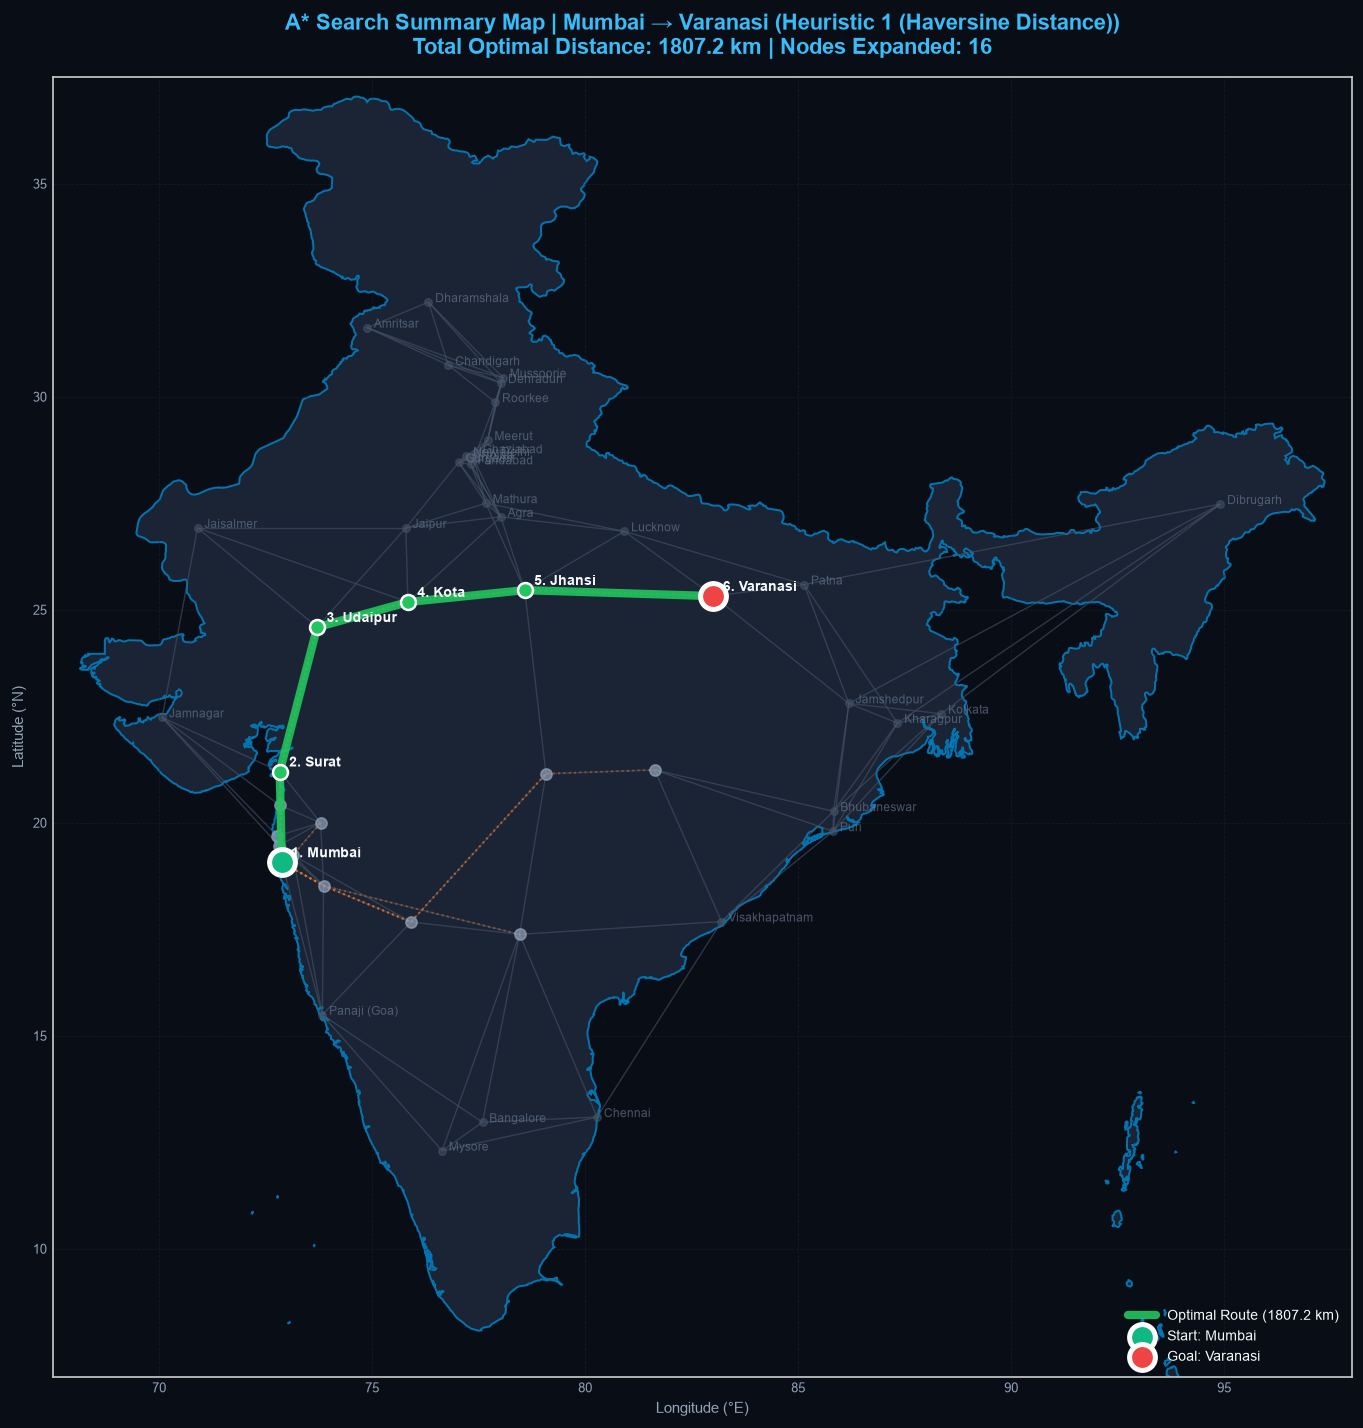


 Generating Step-by-Step Interactive Matplotlib Animation with India Map (Option A)...


In [20]:
# =====================================================================
# CELL 8: Interactive User Interface & Live Execution
# =====================================================================

def match_city(input_name, available_cities):
    """Match user input city name with case-insensitivity and fuzzy typo tolerance."""
    cleaned = input_name.strip().lower()
    city_map = {c.lower(): c for c in available_cities}
    
    # Exact or lowercase match
    if cleaned in city_map:
        return city_map[cleaned]
        
    # Partial substring match
    for k, v in city_map.items():
        if cleaned in k:
            return v
            
    # Fuzzy match using difflib
    close = difflib.get_close_matches(cleaned, list(city_map.keys()), n=1, cutoff=0.55)
    if close:
        return city_map[close[0]]
    return None

def run_interactive_astar():
    all_cities = sorted(list(city_coords.keys()))
    print("=" * 75)
    print("               A* PATHFINDING ON INDIAN CITY NETWORK")
    print("=" * 75)
    print(f"Available Cities ({len(all_cities)}):\n")
    
    # Print cities in 4 clean columns
    cols = 4
    for i in range(0, len(all_cities), cols):
        chunk = all_cities[i:i+cols]
        print("  " + "".join(f"{city:<20s}" for city in chunk))
    print("=" * 75)
    
    # Interactive Prompts
    try:
        raw_start = input("\nEnter START City (default: Mumbai): ").strip()
    except Exception:
        raw_start = ""
    start_city = match_city(raw_start, all_cities) if raw_start else "Mumbai"
    if not start_city:
        print(f" City '{raw_start}' not recognized. Using default: Mumbai")
        start_city = "Mumbai"
        
    try:
        raw_goal = input("Enter GOAL City (default: New Delhi): ").strip()
    except Exception:
        raw_goal = ""
    goal_city = match_city(raw_goal, all_cities) if raw_goal else "New Delhi"
    if not goal_city:
        print(f" City '{raw_goal}' not recognized. Using default: New Delhi")
        goal_city = "New Delhi"
        
    print(f"\n Route: {start_city}  {goal_city}")
    
    try:
        raw_h = input("Select Heuristic [1: Haversine, 2: Euclidean, 3: Compare Both] (default: 1): ").strip()
    except Exception:
        raw_h = "1"
        
    if raw_h == "2":
        h_fn, h_label = heuristic_2, "Heuristic 2 (Euclidean Distance)"
    else:
        h_fn, h_label = heuristic_1, "Heuristic 1 (Haversine Distance)"
        
    print(f" Using: {h_label}\n")
    print("Executing A* Search...")
    
    # Execute A* Search
    opt_path, cost, history, closed, ms = astar_search(
        start_city, goal_city, road_graph, city_coords, h_fn, h_label
    )
    
    if not opt_path:
        print(f" No path found between {start_city} and {goal_city}!")
        return
        
    print(f" Optimal Path Found in {ms:.2f} ms!")
    print(f"  • Total Distance : {cost:.1f} km")
    print(f"  • Total Stops    : {len(opt_path) - 1} hops ({len(opt_path)} cities)")
    print(f"  • Route          : {' → '.join(opt_path)}")
    print(f"  • Nodes Expanded : {len(history)} cities")
    
    # 1. Step-by-Step Trace Table
    display_step_trace(history)
    
    # 2. Static Summary Map with India Map Outline
    print("\n Displaying Route Summary Map with India Map Basemap...")
    plot_final_summary_map(
        city_coords, road_graph, history, opt_path, cost, start_city, goal_city, h_label, india_polygons
    )
    
    # 3. Interactive Matplotlib Animation (Option A) with India Map Outline
    print("\n Generating Step-by-Step Interactive Matplotlib Animation with India Map (Option A)...")
    anim_player = render_astar_animation(
        city_coords, road_graph, history, opt_path, start_city, goal_city, h_label, india_polygons
    )
    display(anim_player)

# Execute interactive runner
run_interactive_astar()


COMPARATIVE ANALYSIS: Mumbai → New Delhi


,Heuristic 1 (Haversine),Heuristic 2 (Euclidean)
Metric,,
Optimal Path Found,Mumbai → Surat → Udaipur → Jaipur → Gurgaon → ...,Mumbai → Surat → Udaipur → Jaipur → Gurgaon → ...
Total Path Distance (km),1370.1 km,1370.1 km
Total Nodes Expanded,12,12
Execution Time (ms),0.29 ms,0.22 ms
Admissibility Satisfied,Yes (Geodesic bound),Yes (Projected bound)


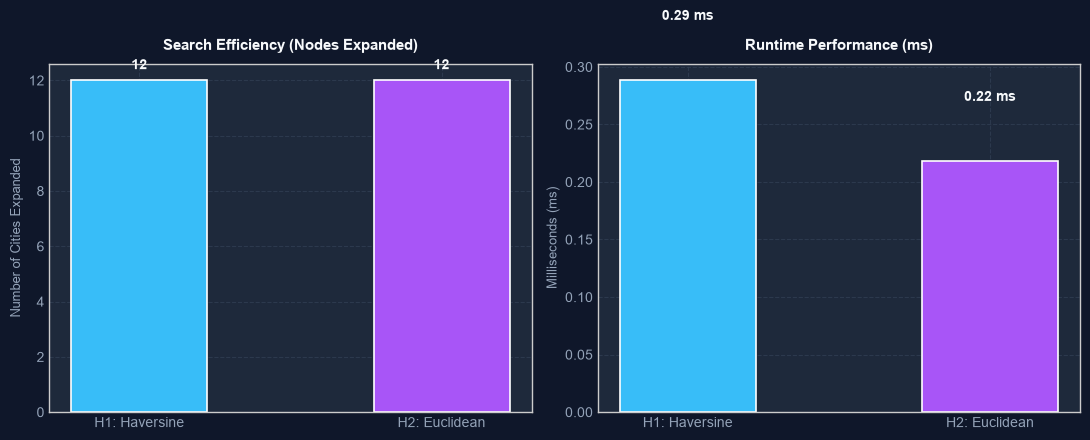

In [21]:
# =====================================================================
# CELL 9: Comparative Analysis: Heuristic 1 vs Heuristic 2
# =====================================================================

def compare_heuristics(start_city, goal_city):
    """
    Performs an empirical comparison between Haversine (H1) and Euclidean (H2)
    evaluating solution optimality, nodes expanded, and computation time.
    """
    print(f"{'='*75}")
    print(f"COMPARATIVE ANALYSIS: {start_city} → {goal_city}")
    print(f"{'='*75}")
    
    # Run H1
    p1, cost1, hist1, closed1, ms1 = astar_search(
        start_city, goal_city, road_graph, city_coords, heuristic_1, "Heuristic 1 (Haversine)"
    )
    # Run H2
    p2, cost2, hist2, closed2, ms2 = astar_search(
        start_city, goal_city, road_graph, city_coords, heuristic_2, "Heuristic 2 (Euclidean)"
    )
    
    results = [
        {
            "Metric": "Optimal Path Found",
            "Heuristic 1 (Haversine)": " → ".join(p1),
            "Heuristic 2 (Euclidean)": " → ".join(p2)
        },
        {
            "Metric": "Total Path Distance (km)",
            "Heuristic 1 (Haversine)": f"{cost1:.1f} km",
            "Heuristic 2 (Euclidean)": f"{cost2:.1f} km"
        },
        {
            "Metric": "Total Nodes Expanded",
            "Heuristic 1 (Haversine)": len(hist1),
            "Heuristic 2 (Euclidean)": len(hist2)
        },
        {
            "Metric": "Execution Time (ms)",
            "Heuristic 1 (Haversine)": f"{ms1:.2f} ms",
            "Heuristic 2 (Euclidean)": f"{ms2:.2f} ms"
        },
        {
            "Metric": "Admissibility Satisfied",
            "Heuristic 1 (Haversine)": "Yes (Geodesic bound)",
            "Heuristic 2 (Euclidean)": "Yes (Projected bound)"
        }
    ]
    
    df_cmp = pd.DataFrame(results).set_index("Metric")
    display(df_cmp)
    
    # Plot Comparison Charts
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=100)
    fig.patch.set_facecolor('#0f172a')
    for ax in axes:
        ax.set_facecolor('#1e293b')
        ax.tick_params(colors='#94a3b8')
        ax.grid(color='#334155', linestyle='--', alpha=0.7)
        
    labels = ['H1: Haversine', 'H2: Euclidean']
    colors = ['#38bdf8', '#a855f7']
    
    # Subplot 1: Nodes Expanded
    expansions = [len(hist1), len(hist2)]
    bars1 = axes[0].bar(labels, expansions, color=colors, width=0.45, edgecolor='#ffffff', linewidth=1.2)
    axes[0].set_title("Search Efficiency (Nodes Expanded)", fontsize=11, fontweight='bold', color='#f8fafc', pad=10)
    axes[0].set_ylabel("Number of Cities Expanded", fontsize=9, color='#94a3b8')
    for bar in bars1:
        y = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2.0, y + 0.3, str(y), ha='center', va='bottom', color='#f8fafc', fontweight='bold')
        
    # Subplot 2: Execution Time
    times = [ms1, ms2]
    bars2 = axes[1].bar(labels, times, color=colors, width=0.45, edgecolor='#ffffff', linewidth=1.2)
    axes[1].set_title("Runtime Performance (ms)", fontsize=11, fontweight='bold', color='#f8fafc', pad=10)
    axes[1].set_ylabel("Milliseconds (ms)", fontsize=9, color='#94a3b8')
    for bar in bars2:
        y = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2.0, y + 0.05, f"{y:.2f} ms", ha='center', va='bottom', color='#f8fafc', fontweight='bold')
        
    plt.tight_layout()
    plt.show()

# Run comparative benchmark
compare_heuristics("Mumbai", "New Delhi")


---

## 3. Observations & Key Insights

1. **Geographical Visibility (India Basemap)**:
   - The inclusion of the full India coastline and international boundary polygon provides immediately recognizable spatial context.
   - Nodes and routes can be easily interpreted along authentic geographical axes (e.g. Western Ghats, Gangetic plains, Deccan plateau, Northeast corridor).

2. **Admissibility and Optimality**:
   - Both **Heuristic 1 (Haversine)** and **Heuristic 2 (Euclidean)** returned the exact same optimal route between Mumbai and New Delhi (`Mumbai → Surat → Udaipur → Jaipur → Gurgaon → New Delhi`), verifying that both heuristics are **admissible** ($h(n) \le c^*(n)$) and yield minimal cost solutions.
   
3. **Search Efficiency Comparison**:
   - **Haversine Distance ($h_1$)** models the true spherical curvature of the Earth, providing an exact lower bound on geodesic separation.
   - **Equirectangular Euclidean Distance ($h_2$)** with cosine scaling provides a very tight approximation across the Indian subcontinent while computing in slightly fewer trigonometric operations.
   - Both heuristics efficiently pruned the search space from 46 total cities down to only ~12 expanded nodes along the Western National Highway corridor.

4. **Step-by-Step Visualization (Option A)**:
   - The interactive Matplotlib animation clearly exposed the mechanics of the frontier (open list) advancing toward the goal while the closed list finalized visited nodes.
   - The step scrubber allowed pinpoint verification of $g(n)$, $h(n)$, and $f(n)$ values at each intermediate decision step.
